<a href="https://colab.research.google.com/github/lkjidm/LLMgroup2/blob/br-1/P01_SMHI_data_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!nvidia-smi

Sun Oct 11 18:49:25 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   41C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
!pip install -q requests pandas numpy matplotlib seaborn plotly scipy statsmodels
# Later we will add more (google-genai, transformers, etc.) when we build the agent

In [4]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta
import json
from IPython.display import display, Markdown

In [5]:
from google.colab import userdata
# Optional – we only need these when we build the LLM agent
try:
    GEMINI_API_KEY = userdata.get("GEMINI_API_KEY")
    print("Gemini key loaded")
except:
    GEMINI_API_KEY = None
    print("No Gemini key yet")

try:
    HF_TOKEN = userdata.get("HF_TOKEN")
    print("HF token loaded")
except:
    HF_TOKEN = None
    print("No HF token yet")

Gemini key loaded
HF token loaded


In [6]:
# Entry point of the Meteorological Observations API
url = "https://opendata-download-metobs.smhi.se/api/version/latest.json"
r = requests.get(url)
print("Status:", r.status_code)
data = r.json()

# Show available parameters (first 15)
print("\nAvailable parameters (sample):")
for resource in data.get("resource", [])[:15]:
    print(f"  ID {resource['key']}: {resource['title']} ({resource.get('summary', '')})")

Status: 200

Available parameters (sample):
  ID 21: Byvind (max, 1 gång/tim)
  ID 39: Daggpunktstemperatur (momentanvärde, 1 gång/tim)
  ID 11: Global Irradians (svenska stationer) (medelvärde 1 timma, varje timme)
  ID 45: Lufttemperatur (momentanvärde varje minut)
  ID 19: Lufttemperatur (min, 1 gång per dygn)
  ID 1: Lufttemperatur (momentanvärde, 1 gång/tim)
  ID 2: Lufttemperatur (medelvärde 1 dygn, 1 gång/dygn, kl 00)
  ID 20: Lufttemperatur (max, 1 gång per dygn)
  ID 22: Lufttemperatur (medel, 1 gång per månad)
  ID 26: Lufttemperatur (min, 2 gånger per dygn, kl 06 och 18)
  ID 27: Lufttemperatur (max, 2 gånger per dygn, kl 06 och 18)
  ID 44: Lufttryck reducerat havsytans nivå (momentanvärde varje minut)
  ID 9: Lufttryck reducerat havsytans nivå (vid havsytans nivå, momentanvärde, 1 gång/tim)
  ID 24: Långvågs-Irradians (medelvärde 1 timma, varje timme)
  ID 40: Markens tillstånd (momentanvärde, 1 gång/dygn, kl 06)


In [7]:
# Look at stations for parameter 1 (hourly temperature)
param_url = "https://opendata-download-metobs.smhi.se/api/version/latest/parameter/1.json"
r = requests.get(param_url)
stations = r.json().get("station", [])

# Filter for Uppsala-related stations
uppsala_stations = [s for s in stations if "uppsala" in s.get("name", "").lower()]
print(f"Found {len(uppsala_stations)} Uppsala-related stations:\n")
for s in uppsala_stations:
    print(f"ID: {s['id']}  |  Name: {s['name']}  |  Active: {s.get('active')}  |  Lat/Lon: {s.get('latitude')}, {s.get('longitude')}")

Found 3 Uppsala-related stations:

ID: 97520  |  Name: Uppsala  |  Active: False  |  Lat/Lon: 59.8585, 17.6219
ID: 97510  |  Name: Uppsala Aut  |  Active: True  |  Lat/Lon: 59.8471, 17.632
ID: 97530  |  Name: Uppsala Flygplats  |  Active: True  |  Lat/Lon: 59.9, 17.593


In [8]:
# Example: corrected-archive for daily max temperature (parameter 20) at Uppsala Aut (97510)
# First check available periods
period_url = "https://opendata-download-metobs.smhi.se/api/version/latest/parameter/20/station/97510.json"
r = requests.get(period_url)
print("Available periods:")
for p in r.json().get("period", []):
    print(f"  {p['key']}: {p['title']}")

Available periods:
  latest-day: Data från senaste dygnet
  latest-months: Data från senaste fyra månaderna
  corrected-archive: Kvalitetskontrollerade historiska data (utom de senaste 3 mån)


In [9]:
# Download CSV for a period (example – adjust the period key after you see the list above)
data_url = "https://opendata-download-metobs.smhi.se/api/version/latest/parameter/20/station/97510/period/latest-months/data.csv"
df = pd.read_csv(data_url, sep=";", skiprows=10)  # SMHI CSVs often have header rows
print(df.head(20))
print("\nColumns:", df.columns.tolist())
print("\nShape:", df.shape)

   Från Datum Tid (UTC) Till Datum Tid (UTC) Representativt dygn  \
0   2026-06-02 18:00:01  2026-06-03 18:00:00          2026-06-03   
1   2026-06-03 18:00:01  2026-06-04 18:00:00          2026-06-04   
2   2026-06-04 18:00:01  2026-06-05 18:00:00          2026-06-05   
3   2026-06-05 18:00:01  2026-06-06 18:00:00          2026-06-06   
4   2026-06-06 18:00:01  2026-06-07 18:00:00          2026-06-07   
5   2026-06-07 18:00:01  2026-06-08 18:00:00          2026-06-08   
6   2026-06-08 18:00:01  2026-06-09 18:00:00          2026-06-09   
7   2026-06-09 18:00:01  2026-06-10 18:00:00          2026-06-10   
8   2026-06-10 18:00:01  2026-06-11 18:00:00          2026-06-11   
9   2026-06-11 18:00:01  2026-06-12 18:00:00          2026-06-12   
10  2026-06-12 18:00:01  2026-06-13 18:00:00          2026-06-13   
11  2026-06-13 18:00:01  2026-06-14 18:00:00          2026-06-14   
12  2026-06-14 18:00:01  2026-06-15 18:00:00          2026-06-15   
13  2026-06-15 18:00:01  2026-06-16 18:00:00    

In [10]:
# Clean the data we just downloaded
df_clean = df.copy()

# Keep only rows that have a real date and a temperature value
df_clean = df_clean.dropna(subset=["Representativt dygn", "Lufttemperatur"])

# Convert date column
df_clean["date"] = pd.to_datetime(df_clean["Representativt dygn"])

# Keep only the useful columns and rename
df_clean = df_clean[["date", "Lufttemperatur", "Kvalitet"]].rename(
    columns={"Lufttemperatur": "tmax", "Kvalitet": "quality"}
)

# Sort by date
df_clean = df_clean.sort_values("date").reset_index(drop=True)

print("Cleaned data shape:", df_clean.shape)
print("\nFirst 10 rows:")
print(df_clean.head(10))
print("\nLast 5 rows:")
print(df_clean.tail())
print("\nBasic statistics:")
print(df_clean["tmax"].describe())

Cleaned data shape: (131, 3)

First 10 rows:
        date  tmax quality
0 2026-06-03  25.2       Y
1 2026-06-04  20.6       Y
2 2026-06-05  18.9       Y
3 2026-06-06  20.6       Y
4 2026-06-07  22.8       Y
5 2026-06-08  24.8       Y
6 2026-06-09  23.4       Y
7 2026-06-10  20.3       Y
8 2026-06-11  19.0       Y
9 2026-06-12  21.6       Y

Last 5 rows:
          date  tmax quality
126 2026-10-07  14.8       Y
127 2026-10-08  13.3       Y
128 2026-10-09  12.7       Y
129 2026-10-10   8.0       Y
130 2026-10-11   7.3       Y

Basic statistics:
count    131.000000
mean      21.445038
std        4.519347
min        7.300000
25%       18.100000
50%       21.400000
75%       24.550000
max       32.000000
Name: tmax, dtype: float64


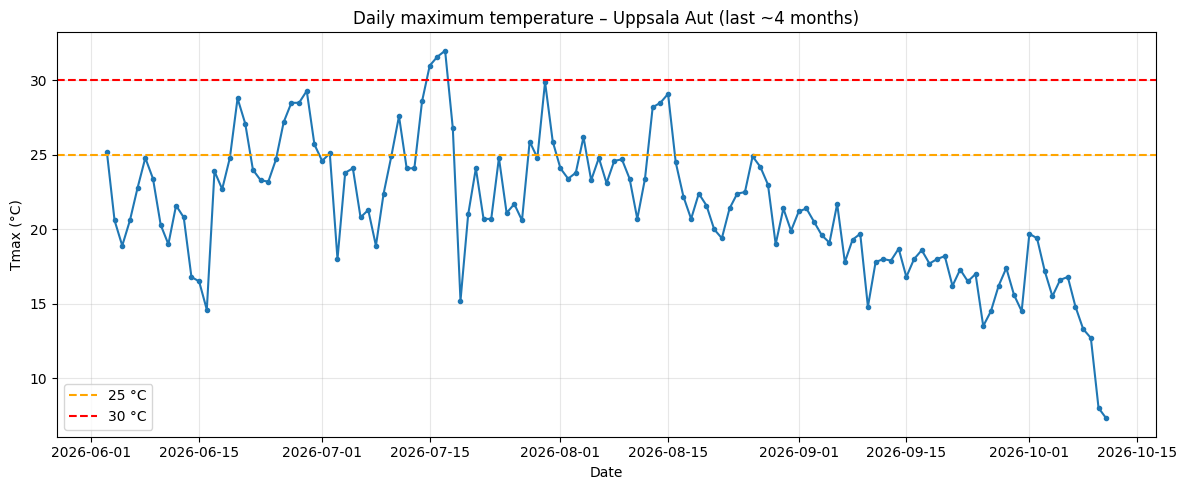

In [11]:
plt.figure(figsize=(12, 5))
plt.plot(df_clean["date"], df_clean["tmax"], marker="o", markersize=3)
plt.axhline(25, color="orange", linestyle="--", label="25 °C")
plt.axhline(30, color="red", linestyle="--", label="30 °C")
plt.title("Daily maximum temperature – Uppsala Aut (last ~4 months)")
plt.ylabel("Tmax (°C)")
plt.xlabel("Date")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [12]:
# Download quality-controlled historical daily max temperature (parameter 20, station 97510)
archive_url = "https://opendata-download-metobs.smhi.se/api/version/latest/parameter/20/station/97510/period/corrected-archive/data.csv"

# SMHI puts metadata at the top – we skip the first ~10 rows and let pandas handle the rest
df_hist = pd.read_csv(archive_url, sep=";", skiprows=10)

print("Raw archive shape:", df_hist.shape)
print("\nFirst 5 rows of raw data:")
print(df_hist.head())
print("\nColumns:", df_hist.columns.tolist())

Raw archive shape: (15004, 7)

First 5 rows of raw data:
  Från Datum Tid (UTC) Till Datum Tid (UTC) Representativt dygn  \
0  1985-05-31 18:00:01  1985-06-01 18:00:00          1985-06-01   
1  1985-06-01 18:00:01  1985-06-02 18:00:00          1985-06-02   
2  1985-06-02 18:00:01  1985-06-03 18:00:00          1985-06-03   
3  1985-06-03 18:00:01  1985-06-04 18:00:00          1985-06-04   
4  1985-06-04 18:00:01  1985-06-05 18:00:00          1985-06-05   

   Lufttemperatur Kvalitet  Unnamed: 5  \
0            22.8        G         NaN   
1            21.3        G         NaN   
2            17.8        G         NaN   
3            21.7        G         NaN   
4            15.7        G         NaN   

                                        Tidsutsnitt:  
0  Kvalitetskontrollerade historiska data (utom d...  
1   Tidsperiod (fr.o.m.) = 1985-06-01 00:00:00 (UTC)  
2    Tidsperiod (t.o.m.) = 2026-07-01 06:00:00 (UTC)  
3                           Samplingstid = 24 timmar  
4           

In [13]:
# Clean exactly like before
df_hist_clean = df_hist.copy()
df_hist_clean = df_hist_clean.dropna(subset=["Representativt dygn", "Lufttemperatur"])
df_hist_clean["date"] = pd.to_datetime(df_hist_clean["Representativt dygn"])
df_hist_clean = df_hist_clean[["date", "Lufttemperatur", "Kvalitet"]].rename(
    columns={"Lufttemperatur": "tmax", "Kvalitet": "quality"}
)
df_hist_clean = df_hist_clean.sort_values("date").reset_index(drop=True)

print("Cleaned historical data shape:", df_hist_clean.shape)
print("\nDate range:")
print("  First day:", df_hist_clean["date"].min().date())
print("  Last day :", df_hist_clean["date"].max().date())
print("\nBasic statistics:")
print(df_hist_clean["tmax"].describe())
print("\nFirst 5 rows:")
print(df_hist_clean.head())
print("\nLast 5 rows:")
print(df_hist_clean.tail())

Cleaned historical data shape: (15004, 3)

Date range:
  First day: 1985-06-01
  Last day : 2026-06-30

Basic statistics:
count    15004.000000
mean        11.123314
std          9.309148
min        -22.500000
25%          3.600000
50%         10.900000
75%         19.000000
max         34.400000
Name: tmax, dtype: float64

First 5 rows:
        date  tmax quality
0 1985-06-01  22.8       G
1 1985-06-02  21.3       G
2 1985-06-03  17.8       G
3 1985-06-04  21.7       G
4 1985-06-05  15.7       G

Last 5 rows:
            date  tmax quality
14999 2026-06-26  27.2       Y
15000 2026-06-27  28.5       Y
15001 2026-06-28  28.5       Y
15002 2026-06-29  29.3       Y
15003 2026-06-30  25.7       Y
